# Workshop 4 — DENOISING IN THE STFT DOMAIN
 - **Student:** Francesc SERRA CRESPÍ
 - **Email:** francesc.serra-crespi@universite-paris-saclay.fr
 - **Master Program:** M2 AI

In [ ]:
import scipy.io.wavfile as wav
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io.wavfile import write
from scipy.signal import stft, istft, windows, get_window, welch, periodogram
from scipy import stats
from itertools import combinations
from scipy.stats import wilcoxon

# 1. CLASS DEFINITION

We define the `signal_data` class, used throughout the previous workshops to efficiently store the main information associated with an audio signal.

Given a `.wav` file, the class automatically stores the **sampling rate**, **signal samples**, **sampling interval**, **number of samples**, **duration**, **time vector**, **Nyquist frequency**, and **frequency resolution**. This provides a common structure for handling both music and noise signals throughout the analysis.

In [22]:
class signal_data: 
    def __init__(self, filename):
        self.filename = filename
        self.rate, self.data = wav.read(filename)
        self.increment = 1 / self.rate
        self.length = len(self.data)
        self.duration = self.length / self.rate
        self.time = np.arange(0, self.length) / self.rate
        self.freq_max = self.rate / 2
        self.resolution_freq = self.rate / self.length


# 2. DATA LOADING
We load both the original music signal and the noise signals that will be used throughout the analysis.
- Noise 1: white noise
- Noise 2: pink noise
- Noise 3: mix of both noises

In [23]:
# Music 
audio_signal = signal_data('data/music.wav')
# Noise 1
noise1 = signal_data('data/noise/noise1.wav')
#Noise 2
noise2 = signal_data('data/noise/noise2.wav')
# Noise 3
noise3 = signal_data('data/noise/noise3.wav')

print('Data of the audio signals:')
print('Music: ', audio_signal.data.shape, 'Noise 1: ', noise1.data.shape, 'Noise 2: ', noise2.data.shape, 'Noise 3: ', noise3.data.shape)
# The noises are specially made for the Music signal, so they have the same length and sampling rate.

Data of the audio signals:
Music:  (140001,) Noise 1:  (140001,) Noise 2:  (140001,) Noise 3:  (140001,)


## 2.1 Welch’s Method for Noise Analysis

Noise: data/noise/noise1.wav, Slope: -0.0 dB/dec
Noise: data/noise/noise2.wav, Slope: -10.0 dB/dec
Noise: data/noise/noise3.wav, Slope: -3.7 dB/dec


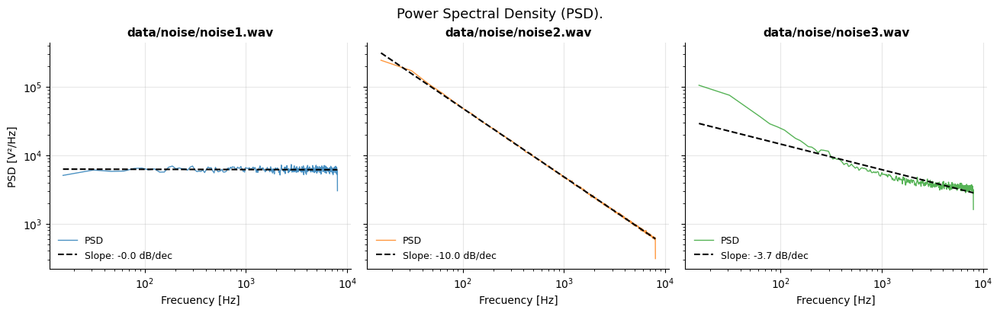

In [24]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(13, 4), constrained_layout=True, sharey=True)
noise_list = [noise1, noise2, noise3]
colors = ["tab:blue", "tab:orange", "tab:green"]

for ax, noise, c in zip(axes, noise_list, colors):
    f, Pxx = welch(noise.data, fs=noise.rate, nperseg=1024)
    f, Pxx = f[1:], Pxx[1:]  

    slope, intercept = np.polyfit(np.log10(f), np.log10(Pxx), 1)
    print(f"Noise: {noise.filename}, Slope: {10*slope:.1f} dB/dec")

    ax.loglog(f, Pxx, color=c, lw=1, alpha=0.8, label="PSD")
    ax.loglog(f, 10**(intercept + slope*np.log10(f)), color='black', ls="--", label=f"Slope: {10*slope:.1f} dB/dec")

    ax.set_title(noise.filename, fontsize=11, fontweight="bold")
    ax.set_xlabel("Frecuency [Hz]")
    ax.grid(True, ls="-", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="lower left")

axes[0].set_ylabel("PSD [V²/Hz]")
fig.suptitle("Power Spectral Density (PSD).", fontsize=13)
plt.show()

# 3. Simulation of Noisy Signals at Different SNR Levels Using the Noises Provided by the Workshop



The noisy signal can be expressed as

$$
y[n] = x[n] + \alpha n[n]
$$

where $x[n]$ is the clean signal, $n[n]$ is the provided noise, and $\alpha$ is a scaling factor that controls the noise amplitude.

The power of the signal is equivalent to:
$$
P_{y} = \frac{1}{N}\sum_{n=0}^{N-1} y[n]^2
$$
as result:
$$
P_{y} = P_x + P_n
$$
The power of the scaled noise is

$$
P_{\alpha n} = \alpha^2 P_n
$$

because multiplying a signal by $\alpha$ multiplies its power by $\alpha^2$.

Substituting this into the definition of SNR gives
$$
{SNR}_{dB}
=
10\log_{10}
\left(
\frac{P_x}{\alpha^2 P_n}
\right)
$$

Solving this expression for $\alpha$ gives

$$
\alpha =
\sqrt{
\frac{P_x}
{P_n\,10^{\mathrm{SNR}_{dB}/10}}
}
$$

Therefore, the procedure consists of calculating the power of both the original signal and the noise, scaling the noise using $\alpha$, and finally adding it to the clean signal.

Using this approach, noisy versions of the original signal are generated for SNR levels ranging from 0 to 25 dB in 3 dB increments, allowing the effect of increasing noise levels on the signal to be analyzed.

In [25]:
def signal_power(x):
    """Mean signal power in the time domain."""
    x = np.asarray(x, dtype=np.float64)
    return np.mean(x**2)

def calculate_snr(clean, test):
    """SNR of test relative to a known clean reference, in dB."""
    clean = np.asarray(clean, dtype=np.float64)
    test = np.asarray(test, dtype=np.float64)
    error = test - clean
    return 10 * np.log10( signal_power(clean) / signal_power(error))


def add_noise_snr(x, noise, snr_db):
    """Scale noise so that y = x + n has the requested SNR."""
    x = np.asarray(x, dtype=np.float64)
    noise = np.asarray(noise, dtype=np.float64)

    Px = signal_power(x)
    Pn = signal_power(noise)

    alpha = np.sqrt( Px / (Pn * 10**(snr_db / 10)))

    noise_scaled = alpha * noise
    y = x + noise_scaled

    return y, noise_scaled

In [26]:
dict_noise_SNR = {}
counter = 1
for noise in [noise1, noise2, noise3]:
    
    noise_power = signal_power(noise.data)
    signal_power_value = signal_power(audio_signal.data)

    print(f"Processing noise: {noise.filename}")
    print(f"\tNoise power: {noise_power:.2f}")
    print(f"\tSignal power: {signal_power_value:.2f}")
    print(f"\tSignal-to-Noise Ratio (SNR): {10 * np.log10(signal_power_value / noise_power):.2f} dB")
    noise_snr_dict = {}
    
    for snr in range(0, 26):
        print(f"\t\tAdded noise with SNR: {snr} dB")

        key=f'SNR_{snr}dB'
        manipulated_signal, scaled_noise = add_noise_snr(audio_signal.data, noise.data, snr)
        length = len(manipulated_signal)
        
        write(f'data/noise/manipulated_signals/noise_{counter}/{key}.wav', audio_signal.rate, manipulated_signal.astype(np.int16))

        snr_in = calculate_snr(audio_signal.data, manipulated_signal)

        print(f"\t\tCalculated SNR: {snr_in:.2f} dB") 
        noise_snr_dict[key] = {'Data': manipulated_signal,'Rate': audio_signal.rate, 'SNR_in': snr_in}
    
    dict_noise_SNR[f'Noise_{counter}'] = noise_snr_dict
    counter += 1

Processing noise: data/noise/noise1.wav
	Noise power: 49387553.63
	Signal power: 56433588.41
	Signal-to-Noise Ratio (SNR): 0.58 dB
		Added noise with SNR: 0 dB
		Calculated SNR: -0.00 dB
		Added noise with SNR: 1 dB
		Calculated SNR: 1.00 dB
		Added noise with SNR: 2 dB
		Calculated SNR: 2.00 dB
		Added noise with SNR: 3 dB
		Calculated SNR: 3.00 dB
		Added noise with SNR: 4 dB
		Calculated SNR: 4.00 dB
		Added noise with SNR: 5 dB
		Calculated SNR: 5.00 dB
		Added noise with SNR: 6 dB
		Calculated SNR: 6.00 dB
		Added noise with SNR: 7 dB
		Calculated SNR: 7.00 dB
		Added noise with SNR: 8 dB
		Calculated SNR: 8.00 dB
		Added noise with SNR: 9 dB
		Calculated SNR: 9.00 dB
		Added noise with SNR: 10 dB
		Calculated SNR: 10.00 dB
		Added noise with SNR: 11 dB
		Calculated SNR: 11.00 dB
		Added noise with SNR: 12 dB
		Calculated SNR: 12.00 dB
		Added noise with SNR: 13 dB
		Calculated SNR: 13.00 dB
		Added noise with SNR: 14 dB
		Calculated SNR: 14.00 dB
		Added noise with SNR: 15 dB
		C

# 4. Heisenberg Uncertainty Principle ($\Delta f \cdot T_{\text{window}}$)
The STFT involves a trade-off between temporal and frequency resolution due to the Heisenberg uncertainty principle. For this reason, we first perform an initial analysis to determine an appropriate window size for the audio signal, seeking a suitable balance between both resolutions. Different window sizes are evaluated, and an elbow analysis is used to identify a reasonable operating point.

The approximate frequency resolution of the STFT is given by:

$$
\Delta f=\frac{f_s}{N_{\text{perseg}}}
$$

while the temporal duration of each analysis window is:

$$
T_{\text{window}}=\frac{N_{\text{perseg}}}{f_s}
$$

Larger windows provide better frequency resolution but poorer temporal resolution, whereas shorter windows allow better localization of changes over time at the cost of reduced frequency resolution.


Sampling rate of the audio signals: 16000
Signal frequency resolution: 0.11428489796501454
Signal Time resolution: 6.25e-05


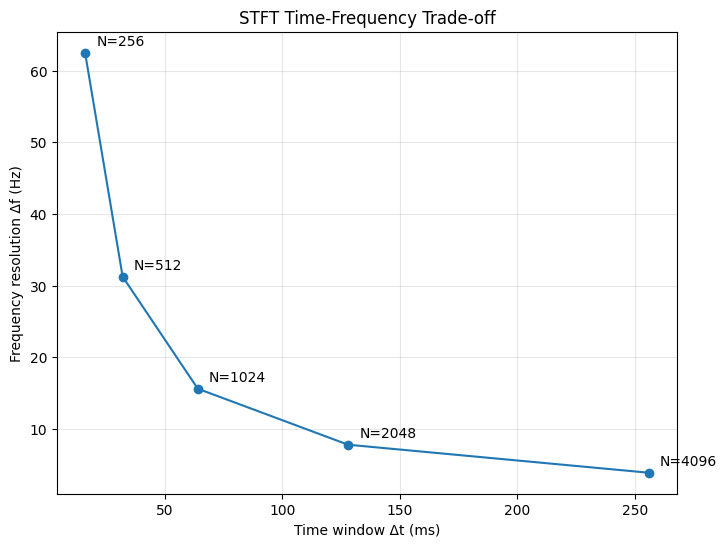

,nperseg,freq_resolution,time_window_ms
0,256,62.50000,16.0
1,512,31.25000,32.0
2,1024,15.62500,64.0
3,2048,7.81250,128.0
4,4096,3.90625,256.0


In [27]:
print('Sampling rate of the audio signals:', audio_signal.rate)
print('Signal frequency resolution:', audio_signal.resolution_freq)
print('Signal Time resolution:', audio_signal.increment)

nperseg_list = [256, 512, 1024, 2048, 4096]

df_window = pd.DataFrame(nperseg_list, columns=['nperseg'])
df_window['freq_resolution'] = (audio_signal.rate / df_window['nperseg'])
df_window['time_window_ms'] = (df_window['nperseg'] / audio_signal.rate * 1000)

plt.figure(figsize=(8, 6))

plt.plot(df_window['time_window_ms'], df_window['freq_resolution'], marker='o')


for _, row in df_window.iterrows():
    plt.annotate( f"N={int(row['nperseg'])}", (row['time_window_ms'], row['freq_resolution']), xytext=(8, 5), textcoords='offset points')

plt.xlabel('Time window Δt (ms)')
plt.ylabel('Frequency resolution Δf (Hz)')
plt.title('STFT Time-Frequency Trade-off')
plt.grid(alpha=0.3)

plt.show()
df_window


### INSIGHTS: STFT time-frequency trade-off

>As shown in the figure, the trade-off between temporal and frequency resolution is not linear. Increasing the window size improves the frequency resolution, but this improvement comes at the cost of a longer time window and therefore poorer temporal localization.
>
>The largest improvements in frequency resolution are observed for smaller window sizes. However, as `nperseg` increases, the improvement becomes progressively smaller while the temporal cost continues to increase. This behavior produces an elbow around `nperseg = 1024`.
>
>For our audio signal, `nperseg = 1024` therefore provides a suitable compromise between both domains. At this point, the STFT achieves a frequency resolution of 15.6 Hz with a time window of 64 ms.  Therefore, `nperseg = 1024` was selected as the operating point.

---

# 5. STFT Analysis

For the STFT analysis, several parameters are considered. After selecting the most appropriate window length for our audio signal, `nperseg = 1024`, the remaining parameters to define are the **window type**, the **overlap**, and the **FFT padding**.

First, different window functions are evaluated, including **Hann**, **Hamming**, and **Blackman**. The amount of overlap between consecutive STFT windows is also evaluated. In this analysis, overlap ratios of **0.50 and 0.75** are considered to assess how the temporal continuity of the spectrogram changes.

Finally, the effect of **zero-padding** in the Fourier transform is considered. Although an FFT length of $2L$ could be used to obtain a denser sampling of the frequency spectrum, this does not increase the actual frequency resolution of the STFT. Since the main objective of this analysis is to evaluate **signal denoising**, zero-padding does not provide a relevant advantage for the functionality being studied. Therefore, we use **$nfft = L$**, with $L$ corresponding to the window length.

## 5.1 Types of Windows

As previously discussed, three different window functions are considered in this analysis: **Hann**, **Blackman**, and **Hamming**. Each window has different properties in terms of **spectral leakage**.

The STFT processing of each segment can be summarized as:

$$
\text{Signal}
\rightarrow
\text{Segmentation}
\rightarrow
\text{Windowing}
\rightarrow
\text{FFT}
\rightarrow
\text{Time-Frequency Representation}
$$

For each segment, the window is applied through a point-wise multiplication:

$$
x_w[n] = x[n]\,w[n]
$$

where $x[n]$ represents the samples of the original segment, $w[n]$ the window coefficients, and $x_w[n]$ the weighted segment used as input to the FFT.

By comparing these three windows, we can evaluate how different weighting distributions affect spectral leakage and the representation of the signal in the frequency domain, which is relevant for the subsequent denoising process.

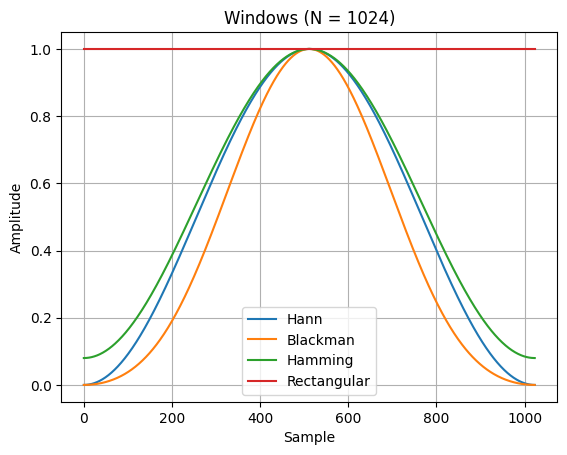

In [28]:

wins = {
    "Hann": windows.hann(1024),
    "Blackman": windows.blackman(1024),
    "Hamming": windows.hamming(1024),
    "Rectangular": windows.boxcar(1024)
}
# Time domain
for name, w in wins.items():
    plt.plot(w, label=name)
plt.title(f"Windows (N = {1024})")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)


### Window insights

>As can be observed, the three windows have a similar overall shape, with a symmetric profile and a maximum weight at the center. However, they differ in how the weights are distributed toward the edges.
>
>The Hamming window presents a noticeable offset along the y-axis, meaning that the weights at the edges do not reach zero, unlike the Hann and Blackman windows. In addition, the three windows show different tapering behavior and curvature, which affects how strongly the samples near the boundaries of each segment are attenuated.
>
>The rectangular window was discarded because it applies an abrupt cut at the segment boundaries. Since the Fourier Transform implicitly assumes that the analyzed segment is periodically repeated, any mismatch between the beginning and the end of the segment creates artificial discontinuities between repetitions. These discontinuities increase spectral leakage, spreading energy into neighboring frequency bins and introducing spurious frequency components.

## 5.2 Short-Time Periodogram (STPSD)

We implemented a **short-time periodogram**, which can be understood as **Welch's method without the final averaging step**:
$$
\text{Noise}
\rightarrow
\text{Segmentation}
\rightarrow
\text{Windowing}
\rightarrow
\text{Periodogram}
\rightarrow
\text{Time-Frequency Representation}
$$

1. The signal is split into **overlapping segments** (`nperseg = 1024`, `noverlap = 512` → `hop = 512`).
2. The **periodogram** of each windowed segment is computed.
3. Instead of **averaging** the periodograms as Welch does, they are kept **side by side in time**, with each column placed at the center of its segment.


The result is a **time–frequency map**, equivalent to the squared magnitude of the STFT scaled as a density.

We apply the STPSD to the **scaled noise actually added to the audio signal** for specific target SNR (0, 12 and 25 dB). Because we use the **same `nperseg` and `hop` as our STFT**, each column corresponds exactly to the same time segment and frequency bins of the STFT. This lets us see **how much noise power each segment of the signal receives**, at each frequency and for each SNR.

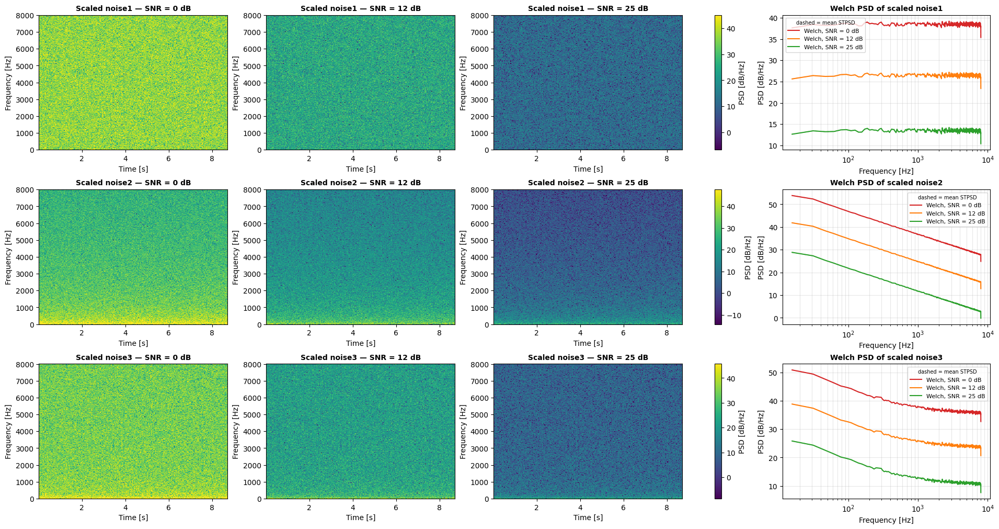

In [29]:
def short_time_periodogram(x, fs, nperseg, noverlap, window="hann"):
    x = np.asarray(x, dtype=float)
    hop = nperseg - noverlap
    n_seg = 1 + (len(x) - nperseg) // hop
    w = get_window(window, nperseg)

    f = np.fft.rfftfreq(nperseg, d=1 / fs)
    Z = np.zeros((len(f), n_seg))
    for k in range(n_seg):
        seg = x[k * hop : k * hop + nperseg]
        seg = (seg - seg.mean()) * w
        _, P = periodogram(seg, fs=fs, window="boxcar", detrend=False, scaling="density")
        Z[:, k] = P * nperseg / np.sum(w**2)

    # Time of each segment = its center, same convention as scipy
    t = (np.arange(n_seg) * hop + nperseg / 2) / fs
    return f, t, Z


list_noise = [noise1, noise2, noise3]
names = ["noise1", "noise2", "noise3"]
snr_list = [0, 12, 25]
nperseg, noverlap = 1024, 512

clean_signal = audio_signal.data


noisy_signals = {}
scaled_noises = {}
for noise, name in zip(list_noise, names):
    for SNR in snr_list:
        noisy, scaled = add_noise_snr(clean_signal, noise.data, SNR)
        noisy_signals[(name, SNR)] = noisy
        scaled_noises[(name, SNR)] = scaled

fig, axes = plt.subplots(len(names), len(snr_list) + 1, figsize=(19, 10),
                         constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})

colors = ["tab:red", "tab:orange", "tab:green"]

for i, (noise, name) in enumerate(zip(list_noise, names)):
    results = []
    for SNR in snr_list:
        x = scaled_noises[(name, SNR)]
        f, t, Pxx = short_time_periodogram(x, fs=noise.rate, nperseg=nperseg,
                                           noverlap=noverlap, window="hann")
        f_w, P_w = welch(x, fs=noise.rate, window="hann", nperseg=nperseg,
                         noverlap=noverlap, detrend="constant", scaling="density")
        results.append((SNR, f, t, Pxx, f_w, P_w))

    db = lambda P: 10 * np.log10(P + 1e-20)
    vmin = min(np.percentile(db(r[3]), 1) for r in results)
    vmax = max(np.percentile(db(r[3]), 99) for r in results)

    for j, (SNR, f, t, Pxx, _, _) in enumerate(results):
        ax = axes[i, j]
        im = ax.pcolormesh(t, f, db(Pxx), shading="auto", cmap="viridis", vmin=vmin, vmax=vmax)
        ax.set_title(f"Scaled {name} — SNR = {SNR} dB", fontsize=10, fontweight="bold")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Frequency [Hz]")
    fig.colorbar(im, ax=axes[i, :len(snr_list)], label="PSD [dB/Hz]")

    ax = axes[i, -1]
    for (SNR, f, _, Pxx, f_w, P_w), c in zip(results, colors):
        ax.semilogx(f_w[1:], db(P_w[1:]), color=c, lw=1.5, label=f"Welch, SNR = {SNR} dB")
        ax.semilogx(f[1:], db(Pxx.mean(axis=1)[1:]), color=c, lw=1, ls="--", alpha=0.8)
    ax.set_title(f"Welch PSD of scaled {name}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("PSD [dB/Hz]")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8, title="dashed = mean STPSD", title_fontsize=7)

plt.show()

### Insights
>
>The SNR changes the **amount of noise**, but not its spectral shape. As the SNR increases, the noise power decreases, while the characteristic frequency distribution of each noise type remains the same. The STPSD and Welch PSD show the same spectral behavior, confirming that the noise remains approximately stationary over time.
>
>Based on these results, we expect the noisy signal STFT to show different patterns depending on the noise type:
>
>- **Noise 1: White noise:** a relatively uniform increase of the background energy across the whole frequency range.
>- **Noise 2: Pink noise:** a stronger increase of the background energy at low frequencies.
>- **Noise 3: Mixed noise:** stronger contamination at low frequencies, with a more uniform noise floor at higher frequencies.
>
>The effect should also depend strongly on the SNR. At **0 dB**, the noise power is comparable to the signal power, so the signal components may be partially masked. As the SNR increases, the noise floor decreases and the original time-frequency structure of the signal should become progressively clearer.

## 5.3 STFT Analysis Across Noise Types, Windows, and Overlap Settings
This pipeline evaluates the Short-Time Fourier Transform (STFT) of the signal across different noise types, overlap values, and window functions in order to compare their effects on the time-frequency representation.

=== NOISE: Noise_1 ===
	Processing SNR_0dB...
	Processing SNR_12dB...
	Processing SNR_25dB...


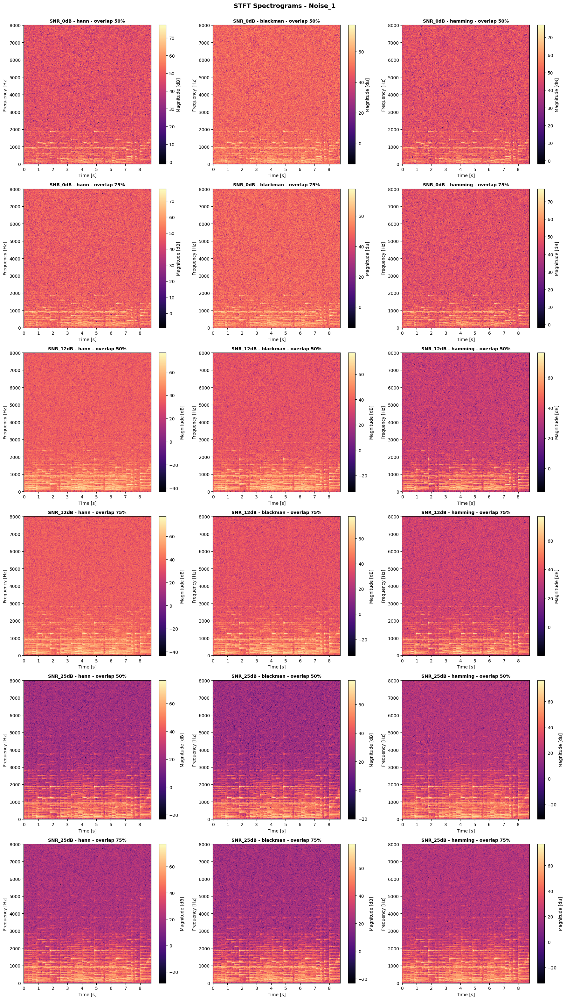

=== NOISE: Noise_2 ===
	Processing SNR_0dB...
	Processing SNR_12dB...
	Processing SNR_25dB...


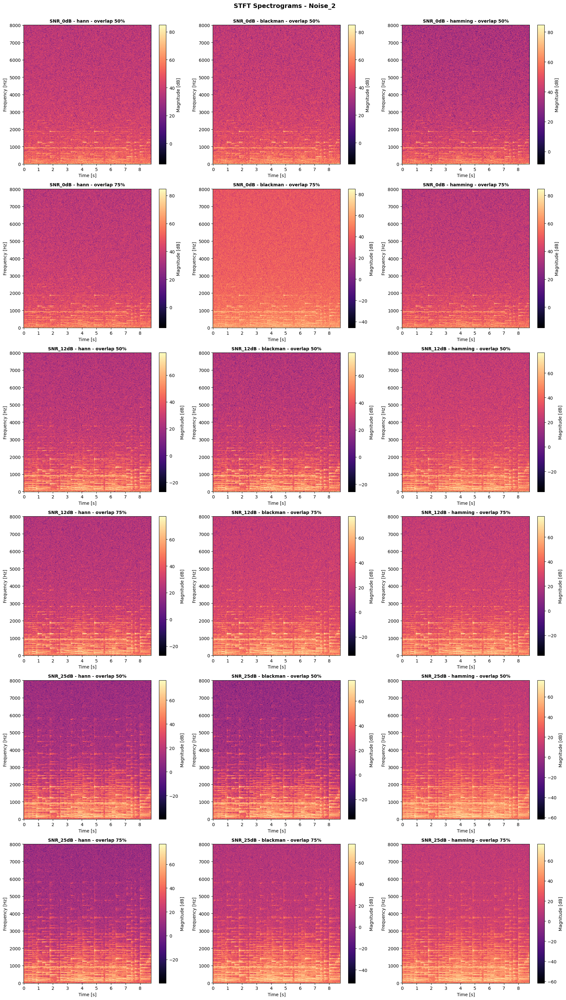

=== NOISE: Noise_3 ===
	Processing SNR_0dB...
	Processing SNR_12dB...
	Processing SNR_25dB...


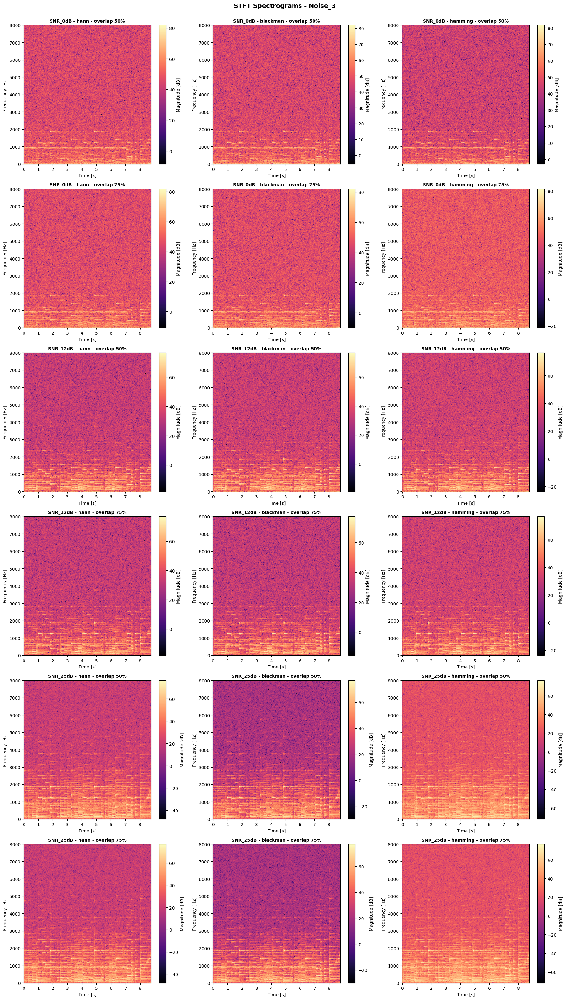

In [30]:
snr_levels = ['SNR_0dB', 'SNR_12dB', 'SNR_25dB']
windows = ["hann", "blackman", "hamming"]
overlaps = [0.5, 0.75]


for noise in dict_noise_SNR:
    print(f"=== NOISE: {noise} ===")
    fig1, axes1 = plt.subplots(nrows=6, ncols=3, figsize=(18, 32), squeeze=False)

    for snr_key in dict_noise_SNR[noise]:
        matches = [i for i, level in enumerate(snr_levels) if level in snr_key]
        if not matches:
            continue

        snr_idx = matches[0]
        print(f"\tProcessing {snr_key}...")

        data = dict_noise_SNR[noise][snr_key]['Data']
        rate = dict_noise_SNR[noise][snr_key]['Rate']

        for win_idx, window in enumerate(windows):
            for ov_idx, overlap in enumerate(overlaps):
                noverlap = int(1024 * overlap)
                ov_tag = f"ov{int(overlap * 100)}"

                f, t, Zxx = stft(data, fs=rate, window=window,
                                    nperseg=1024, 
                                    noverlap=noverlap, 
                                    nfft=1024)

                Zxx_db = 20 * np.log10(np.abs(Zxx))

                title = f"{snr_key} - {window} - overlap {int(overlap*100)}%"

                
                row = snr_idx * 2 + ov_idx
                ax1 = axes1[row, win_idx]
                mesh = ax1.pcolormesh(t, f, Zxx_db, cmap="magma")
                ax1.set_xlabel("Time [s]")
                ax1.set_ylabel("Frequency [Hz]")
                ax1.set_title(title, fontsize=10, fontweight="bold")
                fig1.colorbar(mesh, ax=ax1, label="Magnitude [dB]")

                
                fig_ind, ax_ind = plt.subplots(figsize=(8, 5))
                mesh_ind = ax_ind.pcolormesh(t, f, Zxx_db, cmap="magma")
                ax_ind.set_xlabel("Time [s]")
                ax_ind.set_ylabel("Frequency [Hz]")
                ax_ind.set_title(f"{noise} - {title}", fontsize=10)
                fig_ind.colorbar(mesh_ind, ax=ax_ind, label="Magnitude [dB]")
                fig_ind.savefig(f"figures/{window}/STFT_Spectrograms_{noise}_{snr_key}_{ov_tag}.png", dpi=300, bbox_inches="tight")
                plt.close(fig_ind)

    fig1.suptitle(f"STFT Spectrograms - {noise}", fontsize=14, fontweight="bold")
    fig1.tight_layout(rect=[0, 0, 1, 0.98])
    fig1.savefig(f"figures/STFT_Spectrograms_grid_{noise}.png", dpi=300, bbox_inches="tight")
    plt.show()


### Insights
>The effect of the SNR can be clearly observed in the spectrograms. At low SNR values, the noise masks most of the spectrum, and only the harmonics below approximately **2 kHz** remain clearly visible. As the SNR increases, higher-frequency components that were previously hidden by the noise gradually become visible. At **25 dB**, components can be observed up to around **5–6 kHz**, together with the vertical structures associated with the onset of the notes.
>
>The type of noise also affects the spectrogram, particularly at an **SNR of 0 dB**. White noise (**Noise_1**) has approximately the same power across the frequency spectrum. Since the signal contains less energy at higher frequencies, these components are more easily masked. Pink noise (**Noise_2**), in contrast, contains more energy at low frequencies, leaving the higher-frequency region relatively cleaner and making the upper harmonics easier to identify. The combination of both noises (**Noise_3**) would therefore be expected to show an intermediate behaviour, with stronger noise at low frequencies due to the pink-noise component and some additional noise at higher frequencies due to the white-noise component. However, unlike **Noise_1** and **Noise_2**, this behaviour is not as clearly distinguishable from the spectrograms alone.
>
>Regarding the STFT parameters, there is no clear visual difference between using **50%** and **75% overlap**. This is reasonable, since increasing the overlap mainly changes how frequently the signal is analysed in time, rather than changing the frequency resolution itself.
>
>Differences between the **Hamming**, **Hann**, and **Blackman** windows are not very pronounced in the spectrograms. However, from their theoretical properties, we know that each window distributes the spectral energy differently, so differences are expected mainly in the **magnitude of the frequency components** and in the amount of **spectral leakage**.
>
>Despite these variations, the same general behaviour is observed in all cases: as the SNR increases, the higher-frequency components of the signal become progressively more visible.

# 6. Hard Threshold Filtering

In this section, **hard thresholding** is applied to the STFT coefficients in order to evaluate how much SNR can be recovered after filtering. The objective is to determine the optimal threshold for each combination of **noise type, input SNR, window function, and overlap**.

Let the STFT of the noisy signal be

$$
Z(f,t)=\mathrm{STFT}\{x[n]\},
$$

where $Z(f,t)$ represents the complex STFT coefficient at frequency bin $f$ and time frame $t$.

The threshold is defined as a fraction $\lambda$ of the maximum STFT magnitude:

$$
T_{\lambda}=\lambda Z_{\max},
$$


For this experiment, $\lambda$ is evaluated over 100 equally spaced values between 0 and 1.

The hard-thresholded STFT is therefore defined as

$$
Z_{\lambda}(f,t)=
\begin{cases}
Z(f,t), & |Z(f,t)| \geq \lambda Z_{\max},\\
0, & |Z(f,t)| < \lambda Z_{\max}.
\end{cases}
$$

Thus, increasing $\lambda$ progressively removes STFT coefficients with smaller magnitudes. The filtered signal is then reconstructed using the inverse STFT. For every value of $\lambda$, the output SNR is computed by comparing the reconstructed signal $\hat{x}_{\lambda}[n]$ with the original clean signal. The optimal threshold is selected as the value that maximizes the recovered SNR.

This procedure is repeated for **all available input SNR levels**, noise types, window functions, and overlap configurations. Although the generated figures only display representative input SNR values of **0 dB, 12 dB, and 25 dB** for readability, the threshold optimization is performed over the complete set of SNR modifications.

All results are stored in a dataframe containing the noise type, input SNR, window, overlap, optimal normalized threshold $\lambda^{*}$, corresponding absolute threshold $T^{*}$, output SNR, and SNR gain. This provides a sufficiently large set of observations to subsequently evaluate the effect of the **window function and overlap on denoising performance**.

Processing Noise_1 - SNR_0dB - hann - overlap 0.5...
Processing Noise_1 - SNR_0dB - blackman - overlap 0.5...
Processing Noise_1 - SNR_0dB - hamming - overlap 0.5...
Processing Noise_1 - SNR_1dB - hann - overlap 0.5...
Processing Noise_1 - SNR_1dB - blackman - overlap 0.5...
Processing Noise_1 - SNR_1dB - hamming - overlap 0.5...
Processing Noise_1 - SNR_2dB - hann - overlap 0.5...
Processing Noise_1 - SNR_2dB - blackman - overlap 0.5...
Processing Noise_1 - SNR_2dB - hamming - overlap 0.5...
Processing Noise_1 - SNR_3dB - hann - overlap 0.5...
Processing Noise_1 - SNR_3dB - blackman - overlap 0.5...
Processing Noise_1 - SNR_3dB - hamming - overlap 0.5...
Processing Noise_1 - SNR_4dB - hann - overlap 0.5...
Processing Noise_1 - SNR_4dB - blackman - overlap 0.5...
Processing Noise_1 - SNR_4dB - hamming - overlap 0.5...
Processing Noise_1 - SNR_5dB - hann - overlap 0.5...
Processing Noise_1 - SNR_5dB - blackman - overlap 0.5...
Processing Noise_1 - SNR_5dB - hamming - overlap 0.5...
Proc

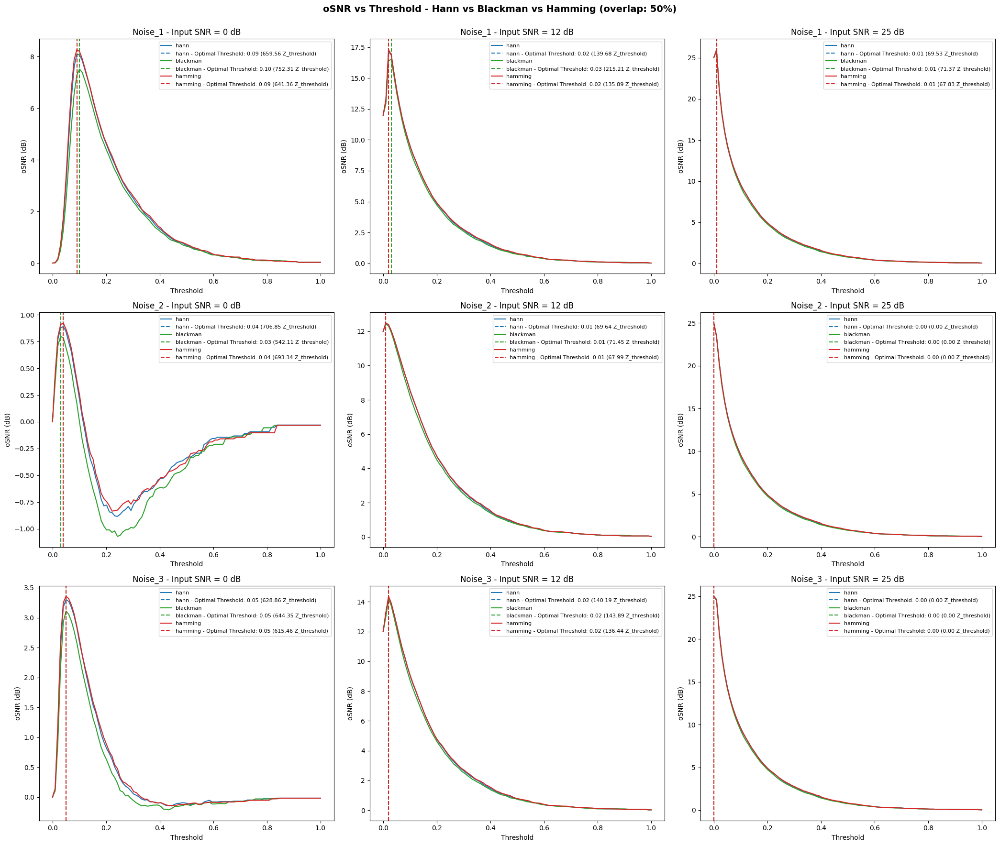

Processing Noise_1 - SNR_0dB - hann - overlap 0.75...
Processing Noise_1 - SNR_0dB - blackman - overlap 0.75...
Processing Noise_1 - SNR_0dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_1dB - hann - overlap 0.75...
Processing Noise_1 - SNR_1dB - blackman - overlap 0.75...
Processing Noise_1 - SNR_1dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_2dB - hann - overlap 0.75...
Processing Noise_1 - SNR_2dB - blackman - overlap 0.75...
Processing Noise_1 - SNR_2dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_3dB - hann - overlap 0.75...
Processing Noise_1 - SNR_3dB - blackman - overlap 0.75...
Processing Noise_1 - SNR_3dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_4dB - hann - overlap 0.75...
Processing Noise_1 - SNR_4dB - blackman - overlap 0.75...
Processing Noise_1 - SNR_4dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_5dB - hann - overlap 0.75...
Processing Noise_1 - SNR_5dB - blackman - overlap 0.75...
Processing Noise_1 - SNR_5dB - hamming - ov

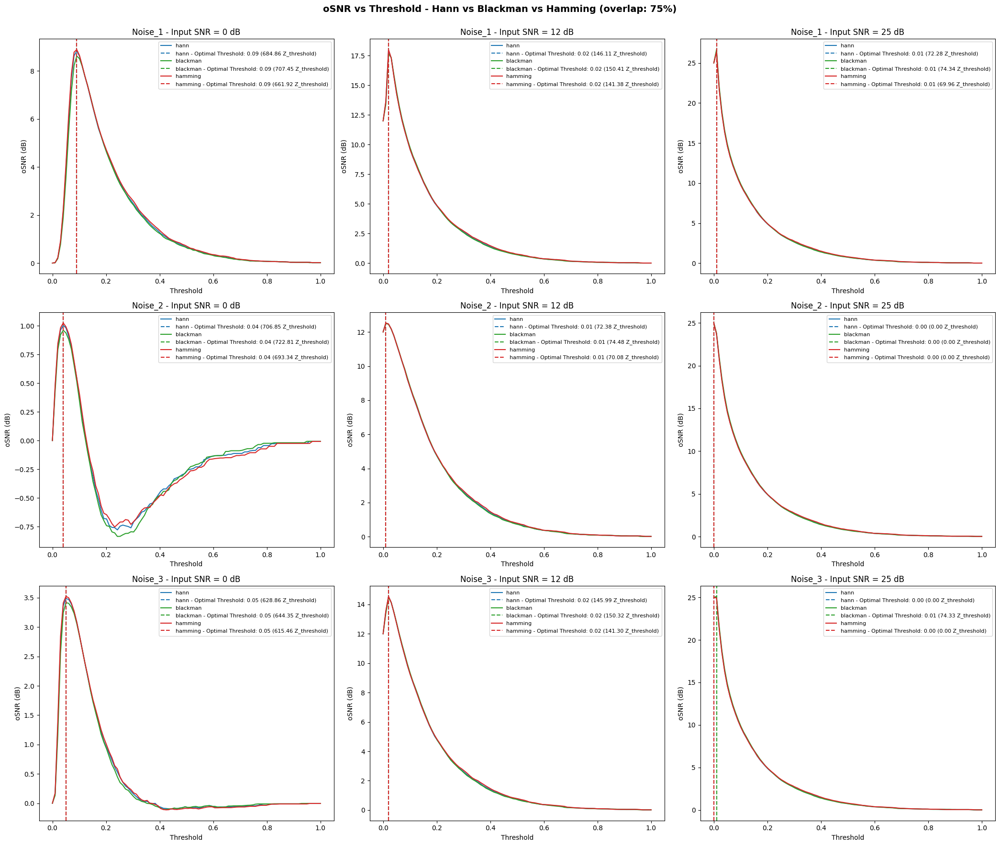

,noise,snr_level,window,overlap,snr_in_dB,optimal_threshold,Z_treshold,snr_out_dB,gain_dB
0,Signal + Noise_1,SNR_0dB,hann,0.50,0,0.090909,659.558861,8.095747,8.095747
1,Signal + Noise_1,SNR_0dB,blackman,0.50,0,0.101010,752.306549,7.514060,7.514060
2,Signal + Noise_1,SNR_0dB,hamming,0.50,0,0.090909,641.364264,8.270857,8.270857
3,Signal + Noise_1,SNR_1dB,hann,0.50,1,0.080808,582.262626,8.813757,7.813757
4,Signal + Noise_1,SNR_1dB,blackman,0.50,1,0.090909,672.497392,8.181622,7.181622
...,...,...,...,...,...,...,...,...,...
463,Signal + Noise_3,SNR_24dB,blackman,0.75,24,0.010101,74.354972,24.571239,0.571239
464,Signal + Noise_3,SNR_24dB,hamming,0.75,24,0.010101,69.973035,24.431139,0.431139
465,Signal + Noise_3,SNR_25dB,hann,0.75,25,0.000000,0.000000,25.000000,0.000000
466,Signal + Noise_3,SNR_25dB,blackman,0.75,25,0.010101,74.325810,25.123554,0.123554


In [31]:
selected_snrs = [0, 12, 25]
thresholds = np.linspace(0, 1, 100)
colors = {"hann": "tab:blue", "blackman": "tab:green", "hamming": "tab:red"}

results = []
n_noises = len(dict_noise_SNR)
nperseg = 1024

for overlap in overlaps:                         
    noverlap = int(nperseg * overlap)            

    fig, axes = plt.subplots(nrows=n_noises, ncols=len(selected_snrs), figsize=(21, 18), squeeze=False)

    for noise_counter, (noise, snr_versions) in enumerate(dict_noise_SNR.items()):
        for snr_key, data in snr_versions.items():
            fs = data['Rate']
            snr_in = round(data['SNR_in'])

            for window in windows:
                print(f"Processing {noise} - {snr_key} - {window} - overlap {overlap}...")   

                _, _, Zxx = stft(data['Data'], fs=fs, window=window, nperseg=nperseg, noverlap=noverlap, nfft=1024)   
                Z_mag = np.abs(Zxx)
                Z_max = Z_mag.max()

                snrs = []
                for threshold in thresholds:
                    Z_filtered = np.where(Z_mag >= threshold * Z_max, Zxx, 0)
                    _, x_filtered = istft(Z_filtered, fs=fs, window=window,
                                          nperseg=nperseg, noverlap=noverlap, nfft=1024)   

                    n = min(len(audio_signal.data), len(x_filtered))
                    snrs.append(calculate_snr(audio_signal.data[:n], x_filtered[:n]))

                best = int(np.argmax(snrs))

                if snr_in in selected_snrs:
                    ax = axes[noise_counter, selected_snrs.index(snr_in)]
                    ax.plot(thresholds, snrs, color=colors[window], label=f"{window}")

                    ax.axvline(
                        thresholds[best],
                        color=colors[window],
                        linestyle='--',
                        label=(f"{window} - Optimal Threshold: {thresholds[best]:.2f} ({thresholds[best] * Z_max:.2f} Z_threshold)"))

                    ax.set_xlabel("Threshold")
                    ax.set_ylabel("oSNR (dB)")
                    ax.set_title(f"{noise} - Input SNR = {snr_in} dB")
                    ax.legend(fontsize=8)

                results.append({
                    'noise': f"Signal + {noise}",
                    'snr_level': snr_key,
                    'window': window,
                    'overlap': overlap,                
                    'snr_in_dB': snr_in,
                    'optimal_threshold': thresholds[best],
                    'Z_treshold': thresholds[best] * Z_max,
                    'snr_out_dB': snrs[best],
                    'gain_dB': snrs[best] - snr_in,
                })

    fig.suptitle(f"oSNR vs Threshold - Hann vs Blackman vs Hamming (overlap: {int(overlap*100)}%)", fontsize=14, fontweight="bold")   
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

df_results_treshold = pd.DataFrame(results)

# Table results
df_results_treshold

## Initial Insights Thresholding 

Before analyzing the performance of the different windows and overlaps, a clear general trend can be observed in the optimal threshold.

As the input SNR increases, the optimal threshold $\lambda$ tends to decrease. At low SNR values, the noise represents a larger proportion of the observed signal, so a higher threshold is beneficial to suppress low-amplitude components mainly associated with noise. In contrast, as the SNR increases, the contribution of noise becomes smaller and less aggressive thresholding is required. This indicates that applying a strong threshold would no longer provide a significant denoising benefit and could instead remove useful low-amplitude components of the original signal.

Therefore, the optimal value of $\lambda$ is strongly dependent on the initial SNR: noisier signals require stronger filtering, while cleaner signals require little or almost no thresholding.

## 6.1 Performance analyisis

### Overlap 50 % vs 75 %

=== OVERLAP: 50% ===


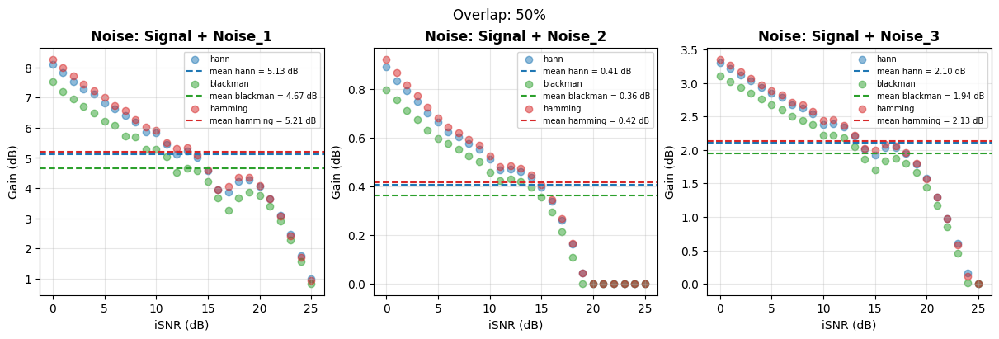

=== OVERLAP: 75% ===


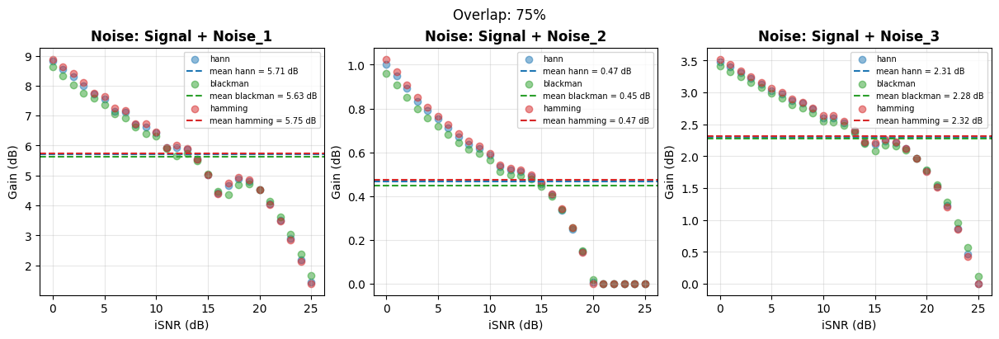

Mean values by noise, window and overlap:


,noise,window,overlap,optimal_threshold,snr_out_dB,gain_dB
0,Signal + Noise_1,blackman,0.50,0.035,17.167,4.667
1,Signal + Noise_1,blackman,0.75,0.032,18.131,5.631
2,Signal + Noise_1,hamming,0.50,0.032,17.712,5.212
3,Signal + Noise_1,hamming,0.75,0.031,18.250,5.750
4,Signal + Noise_1,hann,0.50,0.033,17.625,5.125
5,Signal + Noise_1,hann,0.75,0.031,18.215,5.715
6,Signal + Noise_2,blackman,0.50,0.014,12.863,0.363
7,Signal + Noise_2,blackman,0.75,0.017,12.950,0.450
8,Signal + Noise_2,hamming,0.50,0.015,12.918,0.418
9,Signal + Noise_2,hamming,0.75,0.017,12.974,0.474


In [32]:


for overlap in overlaps:                                             
    print(f"=== OVERLAP: {int(overlap*100)}% ===")                   

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 4), constrained_layout=True, squeeze=False)

    for counter, noise in enumerate(['Signal + Noise_1', 'Signal + Noise_2', 'Signal + Noise_3']):
        ax1 = axes[0, counter]

        for window in windows:
            df_plot = df_results_treshold[(df_results_treshold['noise'] == noise) &
                                          (df_results_treshold['window'] == window) &
                                          (df_results_treshold['overlap'] == overlap)]   


            # iSNR vs Gain
            mean_gain = df_plot['gain_dB'].mean()

            ax1.scatter(df_plot['snr_in_dB'], df_plot['gain_dB'], color=colors[window], alpha=0.5, label=f"{window}")
            ax1.axhline(mean_gain, color=colors[window], linestyle='--', label=f"mean {window} = {mean_gain:.2f} dB")


        ax1.set_title(f"Noise: {noise}", fontsize=12, fontweight="bold")
        ax1.set_xlabel("iSNR (dB)")
        ax1.set_ylabel("Gain (dB)")
        ax1.legend(fontsize=7, loc='best')
        ax1.grid(alpha=0.3)

    fig.suptitle(f"Overlap: {int(overlap*100)}%")                    
    plt.show()


metrics = ['optimal_threshold', 'snr_out_dB', 'gain_dB']
summary_noise = (df_results_treshold.groupby(['noise', 'window', 'overlap'])[metrics].mean().round(3).reset_index())  

print("Mean values by noise, window and overlap:")                  
summary_noise

In [33]:
gain_by_overlap = df_results_treshold.pivot_table(
    index=['noise', 'snr_in_dB', 'window'],
    columns='overlap',
    values='gain_dB',
)[[0.5, 0.75]]


gain_overlap_50 = gain_by_overlap[0.5]
gain_overlap_75 = gain_by_overlap[0.75]
gain_diff_75_vs_50 = gain_overlap_75 - gain_overlap_50

n_pairs = len(gain_diff_75_vs_50)
mean_diff = gain_diff_75_vs_50.mean()
ci95_low, ci95_high = stats.t.interval(
    0.95, n_pairs - 1, loc=mean_diff, scale=stats.sem(gain_diff_75_vs_50)
)
wilcoxon_result = stats.wilcoxon(gain_overlap_75, gain_overlap_50)

global_stats = {
    'n_pairs': n_pairs,
    'mean_gain_50_dB': gain_overlap_50.mean(),
    'mean_gain_75_dB': gain_overlap_75.mean(),
    'mean_diff_dB': mean_diff,
    'ci95_low_dB': ci95_low,
    'ci95_high_dB': ci95_high,
    'wilcoxon_stat': wilcoxon_result.statistic,
    'wilcoxon_p': wilcoxon_result.pvalue,
}

print("=== Global ===")
print(f"Pairs: {n_pairs}")
print(f"Mean gain 50 %: {gain_overlap_50.mean():.3f} dB")
print(f"Mean gain 75 %: {gain_overlap_75.mean():.3f} dB")
print(f"Mean difference (75-50): {mean_diff:.3f} dB  "
      f"IC95% [{ci95_low:.3f}, {ci95_high:.3f}] dB")
print(f"Paired Wilcoxon: W = {wilcoxon_result.statistic:.1f}, "
      f"p = {wilcoxon_result.pvalue:.3g}")


snr_values = gain_by_overlap.index.get_level_values('snr_in_dB')
snr_quartile = pd.qcut(snr_values, q=4, labels=None, duplicates='drop')

quartile_rows = {}
for quartile, gains in gain_by_overlap.groupby(snr_quartile, observed=True):
    q_gain_50 = gains[0.5]
    q_gain_75 = gains[0.75]
    q_gain_diff = q_gain_75 - q_gain_50

    q_n_pairs = len(q_gain_diff)
    q_mean_diff = q_gain_diff.mean()
    q_ci95_low, q_ci95_high = stats.t.interval(
        0.95, q_n_pairs - 1, loc=q_mean_diff, scale=stats.sem(q_gain_diff)
    )
    q_wilcoxon = stats.wilcoxon(q_gain_75, q_gain_50)

    quartile_rows[quartile] = {
        'n_pairs': q_n_pairs,
        'mean_gain_50_dB': q_gain_50.mean(),
        'mean_gain_75_dB': q_gain_75.mean(),
        'mean_diff_dB': q_mean_diff,
        'ci95_low_dB': q_ci95_low,
        'ci95_high_dB': q_ci95_high,
        'wilcoxon_stat': q_wilcoxon.statistic,
        'wilcoxon_p': q_wilcoxon.pvalue,
    }

stats_per_quartile = pd.DataFrame(quartile_rows).T
stats_per_quartile.index.name = 'snr_in_dB_quartile'

print("\n=== Per input-SNR quartile ===")
print(stats_per_quartile.round(3).to_string())

=== Global ===
Pairs: 234
Mean gain 50 %: 2.486 dB
Mean gain 75 %: 2.821 dB
Mean difference (75-50): 0.335 dB  IC95% [0.296, 0.374] dB
Paired Wilcoxon: W = 1.0, p = 2.38e-37

=== Per input-SNR quartile ===
                    n_pairs  mean_gain_50_dB  mean_gain_75_dB  mean_diff_dB  ci95_low_dB  ci95_high_dB  wilcoxon_stat  wilcoxon_p
snr_in_dB_quartile                                                                                                               
(-0.001, 6.0]          63.0            3.634            4.010         0.375        0.292         0.459            0.0         0.0
(6.0, 12.5]            54.0            2.876            3.231         0.355        0.265         0.445            0.0         0.0
(12.5, 19.0]           63.0            2.186            2.519         0.333        0.261         0.405            0.0         0.0
(19.0, 25.0]           54.0            1.105            1.376         0.271        0.201         0.341            1.0         0.0


#### Insight 1: 75% overlap improves the denoising gain, although its effect varies with noise type and input SNR

Overall, using **75% overlap provides better results than 50% overlap**. Across the 234 paired comparisons, the mean gain increases from **2.486 dB** with 50% overlap to **2.821 dB** with 75% overlap, corresponding to an average improvement of **+0.335 dB (95% CI [0.296, 0.374] dB)**. The paired Wilcoxon signed-rank test also shows a highly significant difference (**W = 1.0, p = 2.38 × 10⁻³⁷**), indicating that the advantage of 75% overlap is very consistent across the different configurations rather than being caused by a few isolated cases.

The improvement becomes smaller as the **input SNR increases**. When grouping the results by iSNR quartiles, the average benefit of using 75% overlap decreases progressively:

| iSNR quartile | Mean improvement (75% − 50%) |
|---|---:|
| 0–6 dB | +0.375 dB |
| 6–12.5 dB | +0.355 dB |
| 12.5–19 dB | +0.333 dB |
| 19–25 dB | +0.271 dB |


The effect also changes depending on the **type of noise**. The largest improvement is observed for **Noise 1**, followed by **Noise 3**, while the effect is much smaller for **Noise 2**. Interestingly, **Noise 3**, which combines Noise 1 and Noise 2, shows an intermediate behavior.

### Denoising Performance Across Windows at 75% Overlap


=== Wilcoxon paired test results (overlap = 0.75) ===
              noise                 pair  p_value
0  Signal + Noise_1  blackman vs hamming   0.0067
1  Signal + Noise_1     blackman vs hann   0.0073
2  Signal + Noise_1      hamming vs hann   0.0051
3  Signal + Noise_2  blackman vs hamming   0.0002
4  Signal + Noise_2     blackman vs hann   0.0004
5  Signal + Noise_2      hamming vs hann   0.0002
6  Signal + Noise_3  blackman vs hamming   0.0312
7  Signal + Noise_3     blackman vs hann   0.0407
8  Signal + Noise_3      hamming vs hann   0.0035


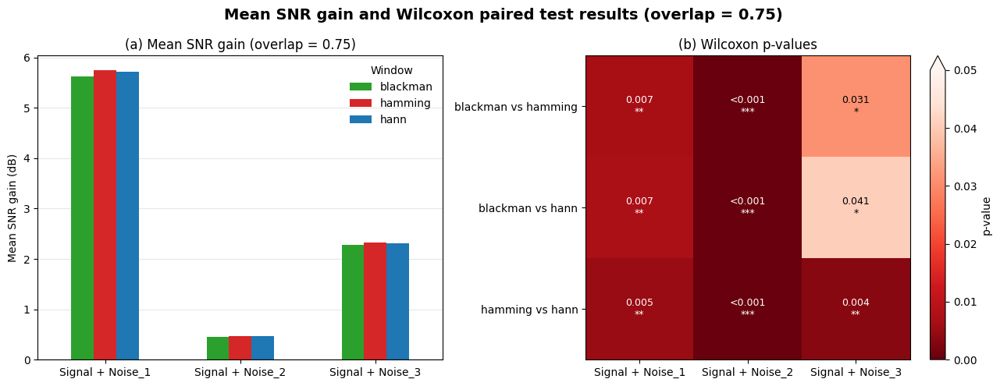

In [34]:

w75 = df_results_treshold[df_results_treshold["overlap"] == 0.75].pivot_table(
    index=["noise", "snr_in_dB"], columns="window", values="gain_dB"
)

windows = list(w75.columns)
noise_means = w75.groupby(level="noise").mean()
noise_std = w75.groupby(level="noise").std()

wilcoxon_results = pd.DataFrame([
    {"noise": noise, "pair": f"{w1} vs {w2}", "p_value": wilcoxon(data[w1], data[w2]).pvalue}
    for noise, data in w75.groupby(level="noise")
    for w1, w2 in combinations(windows, 2)
])

print("\n=== Wilcoxon paired test results (overlap = 0.75) ===")
print(wilcoxon_results.round(4).to_string())

pvalues = wilcoxon_results.pivot(index="pair", columns="noise", values="p_value")

def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

noise_means[windows].plot.bar(ax=ax1, color=colors, rot=0)
ax1.set(xlabel="", ylabel="Mean SNR gain (dB)", title="(a) Mean SNR gain (overlap = 0.75)")
ax1.legend(title="Window", frameon=False)
ax1.grid(axis="y", alpha=0.3)
ax1.set_axisbelow(True)
ax1.axhline(0, color="black", linewidth=0.8)

im = ax2.imshow(pvalues, cmap="Reds_r", vmin=0, vmax=0.05, aspect="auto")

for i in range(pvalues.shape[0]):
    for j in range(pvalues.shape[1]):
        p = pvalues.iloc[i, j]
        label = "<0.001" if p < 0.001 else f"{p:.3f}"
        ax2.text(j, i, f"{label}\n{stars(p)}", ha="center", va="center", fontsize=9,
                 color="white" if p < 0.025 else "black")

ax2.set_xticks(range(pvalues.shape[1]), pvalues.columns)
ax2.set_yticks(range(pvalues.shape[0]), pvalues.index)
ax2.set_title("(b) Wilcoxon p-values")

fig.colorbar(im, ax=ax2, label="p-value", extend="max")
plt.suptitle("Mean SNR gain and Wilcoxon paired test results (overlap = 0.75)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


=== Input SNR range per quartile ===
Q1: (-0.001, 6.0] dB
Q2: (6.0, 12.5] dB
Q3: (12.5, 19.0] dB
Q4: (19.0, 25.0] dB

=== Wilcoxon paired test results per SNR quartile (overlap = 0.75) ===
               noise quartile                 pair  p_value
0   Signal + Noise_1       Q1  blackman vs hamming   0.0156
1   Signal + Noise_1       Q1     blackman vs hann   0.0156
2   Signal + Noise_1       Q1      hamming vs hann   0.0156
3   Signal + Noise_1       Q2  blackman vs hamming   0.0312
4   Signal + Noise_1       Q2     blackman vs hann   0.0312
5   Signal + Noise_1       Q2      hamming vs hann   0.0312
6   Signal + Noise_1       Q3  blackman vs hamming   0.1094
7   Signal + Noise_1       Q3     blackman vs hann   0.1094
8   Signal + Noise_1       Q3      hamming vs hann   0.0781
9   Signal + Noise_1       Q4  blackman vs hamming   0.0625
10  Signal + Noise_1       Q4     blackman vs hann   0.0625
11  Signal + Noise_1       Q4      hamming vs hann   0.0625
12  Signal + Noise_2       Q1 

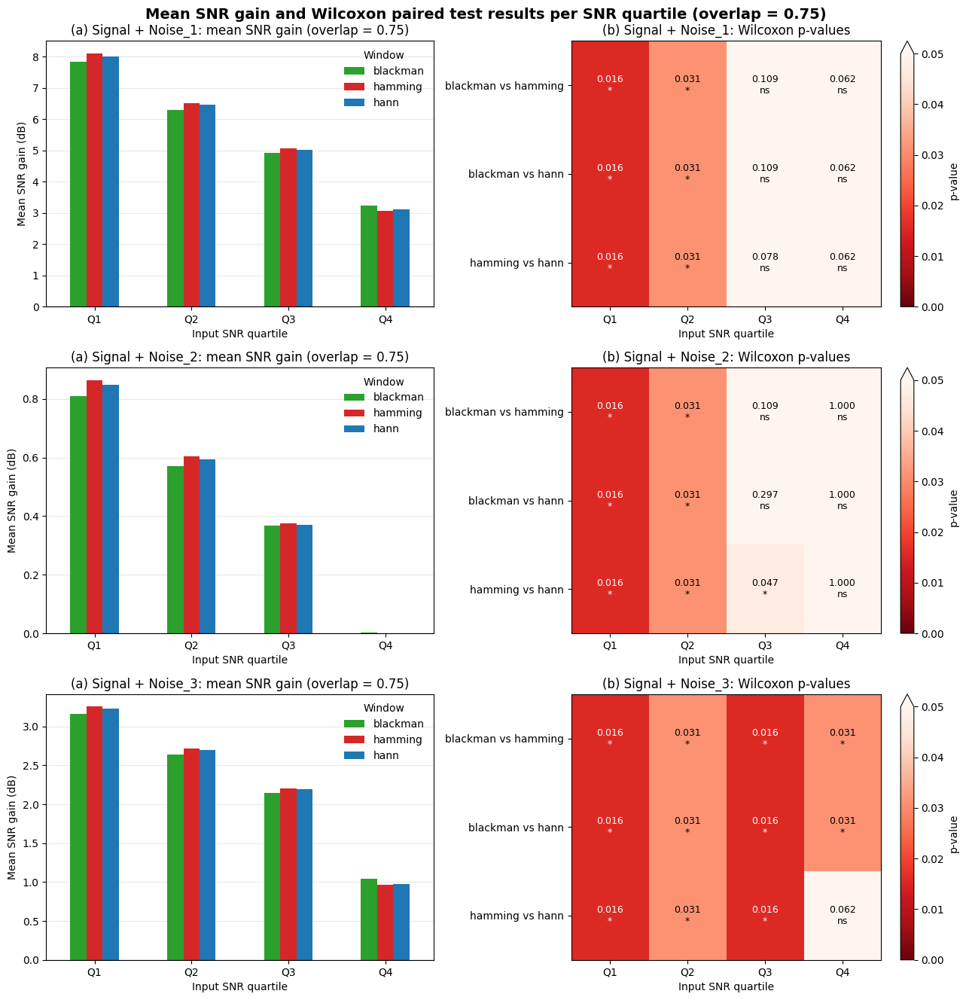

In [35]:
snr = w75.index.get_level_values("snr_in_dB")
quartile_labels = ["Q1", "Q2", "Q3", "Q4"]
w75_q = w75.assign(quartile=pd.qcut(snr, 4, labels=quartile_labels))

print("\n=== Input SNR range per quartile ===")
for q, interval in zip(quartile_labels, pd.qcut(snr, 4).categories):
    print(f"{q}: {interval} dB")

q_means = w75_q.groupby(["noise", "quartile"], observed=True)[windows].mean()

wilcoxon_q = pd.DataFrame([
    {"noise": noise, "quartile": q, "pair": f"{w1} vs {w2}", "p_value": wilcoxon(data[w1], data[w2]).pvalue}
    for (noise, q), data in w75_q.groupby(["noise", "quartile"], observed=True)
    for w1, w2 in combinations(windows, 2)
])

print("\n=== Wilcoxon paired test results per SNR quartile (overlap = 0.75) ===")
print(wilcoxon_q.round(4).to_string())

noises = q_means.index.get_level_values("noise").unique()
fig, axes = plt.subplots(len(noises), 2, figsize=(13, 4.5 * len(noises)), squeeze=False)

for (ax1, ax2), noise in zip(axes, noises):
    q_means.loc[noise].plot.bar(ax=ax1, color=colors, rot=0)
    ax1.set(xlabel="Input SNR quartile", ylabel="Mean SNR gain (dB)",
            title=f"(a) {noise}: mean SNR gain (overlap = 0.75)")
    ax1.legend(title="Window", frameon=False)
    ax1.grid(axis="y", alpha=0.3)
    ax1.set_axisbelow(True)
    ax1.axhline(0, color="black", linewidth=0.8)

    pv = wilcoxon_q[wilcoxon_q["noise"] == noise].pivot(index="pair", columns="quartile", values="p_value")
    im = ax2.imshow(pv, cmap="Reds_r", vmin=0, vmax=0.05, aspect="auto")

    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            p = pv.iloc[i, j]
            label = "<0.001" if p < 0.001 else f"{p:.3f}"
            ax2.text(j, i, f"{label}\n{stars(p)}", ha="center", va="center", fontsize=9,
                     color="white" if p < 0.025 else "black")

    ax2.set_xticks(range(pv.shape[1]), pv.columns)
    ax2.set_yticks(range(pv.shape[0]), pv.index)
    ax2.set(xlabel="Input SNR quartile", title=f"(b) {noise}: Wilcoxon p-values")
    fig.colorbar(im, ax=ax2, label="p-value", extend="max")

plt.suptitle("Mean SNR gain and Wilcoxon paired test results per SNR quartile (overlap = 0.75)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

#### Insights Window Performance 

> ##### Global analysis
> 
> At **75% overlap**, Hamming gives the highest mean SNR gain for the three noise types. The Wilcoxon test shows significant differences between windows when all SNR levels are considered together. However, the differences between windows are still small compared with the much larger effect produced by the noise type itself. This suggests that the characteristics of the noise and the input SNR have a stronger influence on denoising performance than the window choice.
> 
> ##### Quartile analysis
> 
> When the results are separated by input SNR quartiles, the SNR gain clearly decreases as the input SNR increases. In other words, the cleaner the original signal is, the less improvement can be achieved through denoising.
> 
> For **Q1 and Q2**, Hamming generally provides the highest gain, followed very closely by Hann, while Blackman tends to perform slightly worse. These differences are significant in the lowest quartiles for the three noise types.
> 
> At higher SNRs, especially in **Q4**, this behavior changes. Blackman becomes the best-performing window for Noise 1 and Noise 3. For Noise 1, the difference is only a tendency, while for Noise 3 the improvement of Blackman over the other windows is statistically significant. In Noise 2, the gain is already close to zero in Q4, so the differences between windows practically disappear.
> 
> ##### Blackman effect
> 
> This change can be related to the spectral properties of the windows. Hamming has a narrower main lobe, which gives better frequency localization and seems to be more useful when the signal is strongly affected by noise. Blackman has a wider main lobe but much stronger sidelobe attenuation, reducing spectral leakage.
> 
> When the input SNR is high and the signal is already relatively clean, spectral leakage becomes more relevant than noise suppression. In this situation, Blackman's stronger attenuation can become advantageous.
> 
> Overall, **Hamming is the best default option for noisy signals**, but Blackman can become more effective at high input SNR. This shows that the optimal window depends on the noise regime rather than being universal.

---

# 7. Spectral Subtraction

Based on the results of the previous section, and to simplify the analysis, we fix the STFT configuration:

- **75 % overlap**, which provided better results than 50 %.
- **Hamming window**. We do not assume that it is necessarily the optimal window, but its performance was consistently acceptable and is sufficient for this stage.

With the STFT configuration fixed, this section focuses on the spectral subtraction algorithm and the effect of its parameters.

We assume that the observed signal is the sum of the clean signal and additive noise:

$$
z[n] = s[n] + d[n]
\quad\Longrightarrow\quad
Z(k,m) = S(k,m) + D(k,m)
$$

where $k$ is the frequency index and $m$ the time-frame index.

Assuming that the signal and noise are uncorrelated, the power spectrum can be approximated as:

$$
|Z(k,m)|^2 \approx |S(k,m)|^2 + \hat{P}_D(k)
$$

where $\hat{P}_D(k)$ is the estimated noise power spectrum. In this implementation, it is obtained by averaging the noise STFT power over time, and is therefore assumed to remain constant across frames.

### Implementation

Rather than directly modifying the STFT magnitude, the subtraction is expressed through a **power-domain gain**:

$$
G(k,m) =
\max\left(
1 - \alpha \frac{\hat{P}_D(k)}
{|Z(k,m)|^2 },
\beta
\right)
$$

The filtered STFT is then obtained as:

$$
\hat{S}(k,m) = \sqrt{G(k,m)}\,Z(k,m)
$$

The parameter $\alpha$ controls the aggressiveness of the spectral subtraction. Larger values subtract a greater multiple of the estimated noise power, producing stronger denoising but also increasing the risk of removing useful signal components.

The parameter $\beta$ defines the minimum **power gain**, acting as a spectral floor. It prevents the estimated power from being excessively attenuated and avoids completely suppressing time-frequency components. Since the gain is applied to the STFT magnitude through $\sqrt{G(k,m)}$, the corresponding minimum amplitude gain is $\sqrt{\beta}$.

In [36]:
def estimate_noise_power(noise, fs):
    _, _, Z_noise = stft(noise, fs=fs, window="hamming", nperseg=1024, noverlap=768, nfft=1024)
    return np.mean(np.abs(Z_noise)**2, axis=1, keepdims=True)

def spectral_subtraction(Z_stft, noise_power, alpha=4.0, beta=0.03, eps=1e-12):
    Z_power = np.abs(Z_stft)**2
    gain = np.maximum(1 - alpha * noise_power / (Z_power + eps), beta)
    return Z_stft * np.sqrt(gain)

In [37]:

alphas = [1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
betas = [0.0, 0.001, 0.002, 0.003, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.1,
            0.125, 0.15, 0.2, 0.3, 0.4, 1]

results = []

for noise, snr_versions in dict_noise_SNR.items():
    for snr_key, data in snr_versions.items():
        signal = data['Data']
        fs = data['Rate']
        snr_in = data['SNR_in']

        print(f"Processing {noise} - {snr_key} - hamming - overlap 0.75...")

        noise_power = estimate_noise_power(signal - audio_signal.data, fs)
        _, _, Z = stft(signal, fs=fs, window='hamming', nperseg=nperseg, noverlap=int(nperseg * 0.75), nfft=1024)

        for alpha in alphas:
            for beta in betas:
                X_hat = spectral_subtraction(Z, noise_power, alpha=alpha, beta=beta)

                _, x_hat = istft(X_hat, fs=fs, window='hamming', nperseg=nperseg, noverlap=int(nperseg * 0.75), nfft=1024)

                N = min(len(audio_signal.data), len(x_hat))
                snr_out = calculate_snr(audio_signal.data[:N], x_hat[:N])

                results.append({
                    'noise': f'Signal + {noise}',
                    'alpha': alpha,
                    'beta': beta,
                    'snr_level': snr_key,
                    'snr_in_dB': snr_in,
                    'snr_out_dB': snr_out,
                    'gain_dB': snr_out - snr_in,
                })

results_df_expected = pd.DataFrame(results)
results_df_expected

Processing Noise_1 - SNR_0dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_1dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_2dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_3dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_4dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_5dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_6dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_7dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_8dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_9dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_10dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_11dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_12dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_13dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_14dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_15dB - hamming - overlap 0.75...
Processing Noise_1 - SNR_16dB - hamming - overlap 0.75...
Processing Noise_1 - SNR

,noise,alpha,beta,snr_level,snr_in_dB,snr_out_dB,gain_dB
0,Signal + Noise_1,1.0,0.000,SNR_0dB,-4.821637e-16,4.364007,4.364007
1,Signal + Noise_1,1.0,0.001,SNR_0dB,-4.821637e-16,4.313053,4.313053
2,Signal + Noise_1,1.0,0.002,SNR_0dB,-4.821637e-16,4.291223,4.291223
3,Signal + Noise_1,1.0,0.003,SNR_0dB,-4.821637e-16,4.274181,4.274181
4,Signal + Noise_1,1.0,0.005,SNR_0dB,-4.821637e-16,4.246633,4.246633
...,...,...,...,...,...,...,...
34393,Signal + Noise_3,10.0,0.150,SNR_25dB,2.500000e+01,27.592476,2.592476
34394,Signal + Noise_3,10.0,0.200,SNR_25dB,2.500000e+01,27.495181,2.495181
34395,Signal + Noise_3,10.0,0.300,SNR_25dB,2.500000e+01,27.231895,2.231895
34396,Signal + Noise_3,10.0,0.400,SNR_25dB,2.500000e+01,26.927282,1.927282


## Overall Performance of Spectral Subtraction

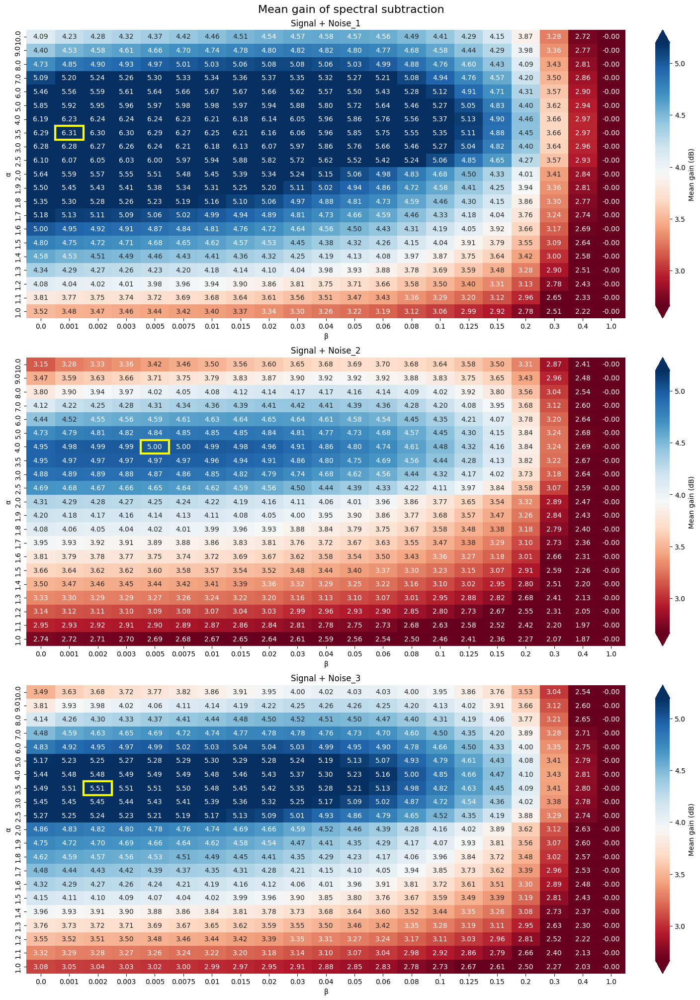

In [38]:
noises = results_df_expected['noise'].unique()

# Mean gain_dB per (noise, alpha, beta), averaged over all SNRs
mean_gain = (results_df_expected
             .groupby(['noise', 'alpha', 'beta'])['gain_dB'] # it does not matter the SNR level, we want to average over all of them
             .mean()
             .reset_index())

# Shared colour scale: overall mean ± std
mu = mean_gain['gain_dB'].mean()
sd = mean_gain['gain_dB'].std()

fig, axes = plt.subplots(3, 1, figsize=(14,20), constrained_layout=True)

for k, (ax, noise) in enumerate(zip(axes, noises)):
    pivot = (mean_gain[mean_gain['noise'] == noise]
             .pivot(index='alpha', columns='beta', values='gain_dB')
             .reindex(index=alphas, columns=betas))

    sns.heatmap(pivot, ax=ax, annot=True, fmt='.2f',
                cmap='RdBu', center=mu, vmin=mu - sd, vmax=mu + sd,
                cbar_kws={'label': 'Mean gain (dB)', 'extend': 'both'})

    # Highlight the highest cell
    i, j = np.unravel_index(np.nanargmax(pivot.values), pivot.shape)
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='yellow', lw=3, clip_on=False))

    ax.set_title(noise)
    ax.invert_yaxis()
    ax.set_xlabel('β')
    ax.set_ylabel('α')

fig.suptitle('Mean gain of spectral subtraction', fontsize=16)
plt.show()

### Insights Spectral subtraction 

> Has we can see in the heatmaps **α has a much stronger effect than β.** Changing α produces clear differences in the gain, while small changes in β have a much smaller impact. β mainly becomes important when it gets too large, since high values reduce the amount of noise removed. At β = 1, the gain becomes 0 dB, which is equivalent to leaving the signal unchanged.
>
> **There is a clear optimal range for α.** For the three noise types, the best results are obtained with α around 3.5–4. Increasing α beyond this point makes the subtraction too aggressive, so part of the useful signal also starts to be removed and the gain decreases.
>
> **A small β works slightly better than β = 0.** The best configurations use β values between 0.001 and 0.005. The improvement in SNR gain is very small, but keeping a small spectral floor helps avoid completely suppressing low-energy frequency components. As α increases, the optimal β also tends to increase.
>
> **Spectral subtraction performs better than hard thresholding overall.**
>
>| Noise | Hard threshold (mean) | α | β | Spectral subtraction (optimum) | Improvement |
>|---|---:|---:|---:|---:|---:|
>| Noise_1 | ≈ 5.70 dB | 3.5 | 0.001 | 6.31 dB | +0.6 dB |
>| Noise_2 | ≈ 0.46 dB | 4.0 | 0.005 | 5.00 dB | +4.5 dB |
>| Noise_3 | ≈ 2.30 dB | 3.5 | 0.002 | 5.51 dB | +3.2 dB |
>
>The biggest difference appears for Noise_2, where hard thresholding provides almost no improvement, while spectral subtraction reaches around 5 dB. The improvement is also clear for Noise_3. For Noise_1, both methods perform more similarly, with spectral subtraction providing only a small additional gain. This is expected because Noise_1 is white noise, with energy spread quite uniformly across frequencies, so a hard threshold can identify and remove much of the low-amplitude noise effectively. For the more frequency-dependent Noise_2 and Noise_3, spectral subtraction is better able to adapt the amount of attenuation across the spectrum.

## Mean Optimal Gain Across Input SNR Quartiles

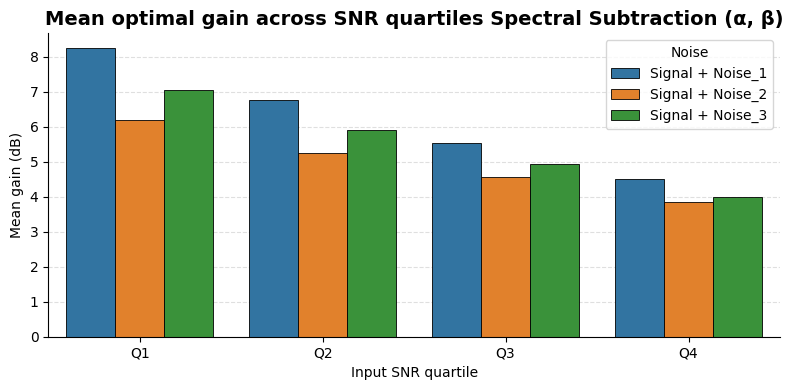

In [39]:
best = results_df_expected.loc[
    results_df_expected.groupby(['noise','snr_in_dB'])['gain_dB'].idxmax()
].copy()

best['quartile'] = pd.qcut(best['snr_in_dB'], 4, labels=['Q1','Q2','Q3','Q4'])

mean_gain_q = (best.groupby(['noise','quartile'], observed=True)['gain_dB']
              .mean().reset_index())

plt.figure(figsize=(8,4))

sns.barplot(data=mean_gain_q, x='quartile', y='gain_dB', hue='noise',
            edgecolor='black', linewidth=0.6)

plt.title('Mean optimal gain across SNR quartiles Spectral Subtraction (α, β)', fontsize=14, fontweight='bold')
plt.xlabel('Input SNR quartile')
plt.ylabel('Mean gain (dB)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.gca().set_axisbelow(True)

sns.despine()
plt.legend(title='Noise')
plt.tight_layout()
plt.show()

### Insights Performance Across SNR Levels

> **The gain decreases as the input SNR increases.** The largest improvements are obtained in Q1, where the signal is more strongly corrupted and there is more noise to remove. As the input SNR increases toward Q4, the gain progressively decreases for all three noise types because the original signal is already cleaner and there is less room for improvement.
>
> **Spectral subtraction remains effective even at high SNR values.** Although the gain is lower in Q4, it still reaches around **4–4.5 dB** for the three noise types. This shows that the method can still remove part of the residual noise even when the input signal is already relatively clean.
>
> **The advantage over hard thresholding becomes especially clear in Q4.** Hard thresholding provides only a small improvement at high SNR, and almost no gain for Noise_2, while spectral subtraction still produces a noticeable increase in SNR. This suggests that spectral subtraction is better at dealing with weak residual noise that is harder to separate using only an amplitude threshold.

## Evolution of Optimal α and β with Input SNR

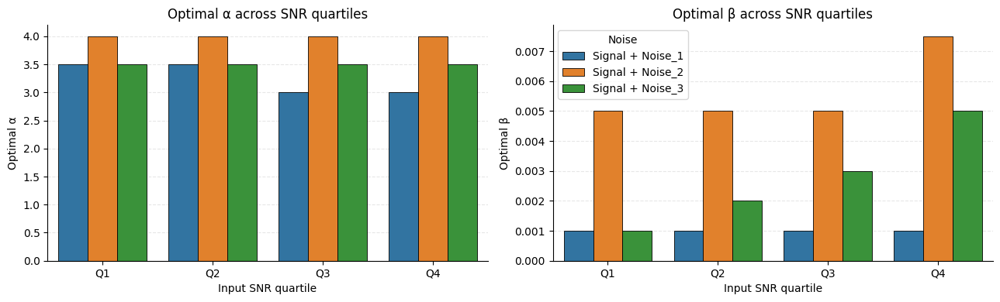

In [40]:
df = results_df_expected.copy()
df['quartile'] = pd.qcut(df['snr_in_dB'], 4, labels=['Q1','Q2','Q3','Q4'])

# Mean gain for each (noise, quartile, alpha, beta)
q_gain = (df.groupby(['noise','quartile','alpha','beta'], observed=True)['gain_dB']
          .mean().reset_index())

# Best alpha-beta pair within each noise × quartile
best_q = q_gain.loc[
    q_gain.groupby(['noise','quartile'], observed=True)['gain_dB'].idxmax()
].reset_index(drop=True)
fig, ax = plt.subplots(1, 2, figsize=(13,4))

sns.barplot(data=best_q, x='quartile', y='alpha', hue='noise',
            errorbar=None, edgecolor='black', linewidth=0.6, ax=ax[0])

sns.barplot(data=best_q, x='quartile', y='beta', hue='noise',
            errorbar=None, edgecolor='black', linewidth=0.6, ax=ax[1])

ax[0].set(title='Optimal α across SNR quartiles',
          xlabel='Input SNR quartile', ylabel='Optimal α')

ax[1].set(title='Optimal β across SNR quartiles',
          xlabel='Input SNR quartile', ylabel='Optimal β')

for a in ax:
    a.grid(axis='y', linestyle='--', alpha=0.3)
    a.set_axisbelow(True)

ax[0].legend_.remove()
ax[1].legend(title='Noise')

sns.despine()
plt.tight_layout()
plt.show()

## Insights: $\alpha$ and $\beta$ across SNR quartiles
>
> The plot help us to determine the followin elements: **the optimal $\alpha$ depends mainly on the noise type rather than on the input SNR.** Pink noise consistently requires the strongest subtraction, with $\alpha=4.0$, while mixed noise remains around $\alpha=3.5$. White noise is the only case where $\alpha$ decreases at higher SNRs, from 3.5 to 3.0, suggesting that stronger oversubtraction is more useful when the signal is highly corrupted.
>
> **The optimal $\beta$ is more sensitive to both noise type and input SNR.** For white noise, the minimum spectral floor, $\beta=0.001$, is sufficient across all quartiles. In contrast, noises containing a pink component require progressively larger $\beta$ values, especially at higher SNRs. A larger spectral floor prevents excessive attenuation and helps preserve weak signal components.
>
> **As the input SNR increases, the optimal filtering becomes more conservative.** For white noise, this is reflected by a reduction in $\alpha$, while for colored noises it mainly appears as an increase in $\beta$. In other words, strongly corrupted signals benefit from more aggressive noise subtraction, whereas cleaner signals require greater preservation of the original spectrum.
>
> **Overall, the results suggest that a single $(\alpha,\beta)$ pair is not optimal for all conditions.** The subtraction factor $\alpha$ should mainly be adapted to the **noise characteristics**, while the spectral floor $\beta$ should account for both the **noise type and the input SNR**.

# 8. General Conclusions

### 1. The performance of hard thresholding depends strongly on the noise type

> Hard thresholding works well for white noise, moderately for mixed noise and barely improves the signal with pink noise (≈ 5.7 dB vs. less than 0.5 dB of mean gain). A single global threshold can separate the music from a flat noise floor. Pink noise, however, concentrates its energy at low frequencies, where most of the musical energy also lies, so noise and signal cannot be separated by amplitude alone.

### 2. The window settings have a small but consistent effect

> In absolute terms, the choice of window and overlap barely changes the gain (a few tenths of a dB), much less than the noise type or the input SNR. However, the differences are consistent: 75 % overlap is systematically better than 50 %, and its relative benefit grows as the input SNR increases. Hamming and Hann perform best on noisy signals, while Blackman becomes competitive at high SNR.

### 3. Spectral subtraction is more robust than hard thresholding

> Spectral subtraction outperforms hard thresholding for the three noises, reaching around 5–6 dB in all cases. The advantage is largest for pink noise, exactly where thresholding fails. Because it uses a frequency-dependent noise estimate, it adapts to the shape of the noise spectrum, so its performance depends much less on the noise type. It also degrades less as the input SNR increases: at high SNR it still gives a clear gain, while the gain of thresholding drops sharply.

### 4. The optimal parameters depend on the conditions

> In both methods, the gain decreases as the input SNR increases and the optimal filtering becomes more conservative: noisy signals benefit from aggressive filtering, while cleaner signals need their weak components preserved. In spectral subtraction, α matters much more than β, and its optimal value depends mainly on the noise type. No single set of parameters is optimal for every case.
